In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

In [ ]:
df = pd.read_excel("/content/SimulasiData-edited-051225 (1).xlsx")

df.head()

,No,Vessel Name,OPR,Month,Week (ATD),ATB,ATD,Shipping Line,Total Teus,Moves,...,Crane Ratio,Crane Idle,BPR (mph),BCH (ET) (bph),QUAY CRANE BREAKDOWN,WAITING CONTAINER,WAITING INTERNAL TRUCK,GEAR BOX HANDLING,BAD WEATHER,SYSTEM FAILURE
0,1,YM INTELLIGENT,YML,Januari,1,2019-01-01 02:00:00,2019-01-01 22:38:00,YML,1183.00,806,...,2.052356,8.73,39.063005,25.858458,1.98,0.02,0.11,0.15,0.0,0.0
1,2,SINGAPORE BRIDGE,MCC,Januari,1,2019-01-01 07:25:00,2019-01-02 09:00:00,MCC,1612.00,1045,...,3.634055,15.15,40.846906,13.944847,0.36,0.21,0.00,0.18,0.0,0.0
2,3,MP THE LAW,MCC,Januari,1,2019-01-02 22:55:00,2019-01-03 08:30:00,MCC,509.25,295,...,2.805755,2.75,30.782609,16.498346,0.08,0.14,0.00,0.17,0.0,0.0
3,4,GSL KETA,CMA,Januari,1,2019-01-04 01:55:00,2019-01-04 13:30:00,CMA,77.00,57,...,1.000000,3.35,4.920863,NaN,0.00,0.00,0.00,0.26,0.0,0.0
4,5,ARICA BRIDGE,SA,Januari,1,2019-01-04 22:00:00,2019-01-06 22:00:00,SA,2859.00,2177,...,4.240482,51.70,45.354167,16.808300,0.34,0.22,0.19,0.30,0.0,0.0


In [ ]:
print("Shape:", df.shape)

Shape: (810, 23)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 810 entries, 0 to 809
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   No                      810 non-null    int64         
 1   Vessel Name             807 non-null    object        
 2   OPR                     807 non-null    object        
 3   Month                   807 non-null    object        
 4   Week (ATD)              810 non-null    object        
 5   ATB                     807 non-null    datetime64[ns]
 6   ATD                     807 non-null    datetime64[ns]
 7   Shipping Line           807 non-null    object        
 8   Total Teus              810 non-null    float64       
 9   Moves                   810 non-null    int64         
 10  Berth Time              810 non-null    float64       
 11  Berth Working Time      810 non-null    float64       
 12  Gross Crane Time        807 non-null    float64   

In [ ]:
missing = df.isnull().sum()

missing[missing > 0]

,0
Vessel Name,3
OPR,3
Month,3
ATB,3
ATD,3
Shipping Line,3
Gross Crane Time,3
Crane Ratio,3
Crane Idle,3
BCH (ET) (bph),71


In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent[missing_percent > 0].sort_values(ascending=False)

,0
BCH (ET) (bph),8.765432
Vessel Name,0.370370
Month,0.370370
OPR,0.370370
ATD,0.370370
Shipping Line,0.370370
Gross Crane Time,0.370370
ATB,0.370370
Crane Ratio,0.370370
Crane Idle,0.370370


In [ ]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percent
}).query("`Missing Values` > 0").sort_values(
    "Missing Values",
    ascending=False
)

,Missing Values,Percentage
BCH (ET) (bph),71,8.765432
Vessel Name,3,0.370370
Month,3,0.370370
OPR,3,0.370370
ATD,3,0.370370
Shipping Line,3,0.370370
Gross Crane Time,3,0.370370
ATB,3,0.370370
Crane Ratio,3,0.370370
Crane Idle,3,0.370370


In [ ]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['No', 'Vessel Name', 'OPR', 'Month', 'Week (ATD)', 'ATB', 'ATD', 'Shipping Line', 'Total Teus', 'Moves', 'Berth Time', 'Berth Working Time', 'Gross Crane Time', 'Crane Ratio', 'Crane Idle', 'BPR (mph)', 'BCH (ET) (bph)', 'QUAY CRANE BREAKDOWN', 'WAITING CONTAINER', 'WAITING INTERNAL TRUCK', 'GEAR BOX HANDLING', 'BAD WEATHER', 'SYSTEM FAILURE']


In [ ]:
df = df.dropna(
    subset=[
        "Vessel Name",
        "OPR",
        "Month",
        "ATB",
        "ATD",
        "Shipping Line",
        "Gross Crane Time",
        "Crane Ratio",
        "Crane Idle"
    ]
)

In [ ]:
df["BCH (ET) (bph)"] = df["BCH (ET) (bph)"].fillna(
    df["BCH (ET) (bph)"].median()
)

/tmp/ipykernel_3025/3845912780.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["BCH (ET) (bph)"] = df["BCH (ET) (bph)"].fillna(


In [ ]:
print("Shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

Shape: (807, 23)
Total missing values: 0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
No,807.0,136.98513,1.0,68.0,135.0,202.0,296.0,80.865647
ATB,807,2020-05-27 10:07:59.107806720,2019-01-01 02:00:00,2019-08-22 16:57:30,2020-06-10 07:25:00,2021-02-06 17:23:30,2021-12-29 09:25:00,NaN
ATD,807,2020-05-28 08:08:21.115241728,2019-01-01 22:38:00,2019-08-23 06:39:00,2020-06-10 19:30:00,2021-02-08 04:13:30,2021-12-30 06:00:00,NaN
Total Teus,807.0,1074.940211,0.0,270.0,699.0,1754.0,6314.0,985.118274
Moves,807.0,742.142503,0.0,210.5,524.0,1153.0,4244.0,670.823795
Berth Time,807.0,22.006113,2.733333,11.708333,18.916667,28.691667,208.483333,14.783434
Berth Working Time,807.0,17.850743,0.0,7.941667,14.95,24.916667,108.383333,13.804269
Gross Crane Time,807.0,48.434511,0.0,13.75,32.5,73.0,318.2,46.621568
Crane Ratio,807.0,2.330351,0.0,1.627223,2.39777,2.938534,13.27212,1.044627
Crane Idle,807.0,9.568779,0.0,2.016667,6.35,13.058333,97.05,11.260318


In [ ]:
df[[
    "Vessel Name",
    "OPR",
    "Month",
    "Shipping Line"
]].nunique()

,0
Vessel Name,195
OPR,32
Month,16
Shipping Line,31


In [ ]:
df["BCH (ET) (bph)"].sort_values().head(10)

,BCH (ET) (bph)
710,-105.736951
103,-59.611554
758,0.000000
620,0.000000
672,0.000000
636,0.000000
101,0.000000
331,0.000000
662,0.000000
284,0.000000


In [ ]:
df["BCH (ET) (bph)"].sort_values(ascending=False).head(10)

,BCH (ET) (bph)
744,617.856018
260,170.000000
112,120.000000
146,110.000000
362,66.666667
324,51.111111
180,44.990657
676,44.696569
603,38.738581
414,36.982258


In [ ]:
print("Negative BCH:", (df["BCH (ET) (bph)"] < 0).sum())
print("Zero BCH:", (df["BCH (ET) (bph)"] == 0).sum())

Negative BCH: 2
Zero BCH: 9


In [ ]:
features = [
    "Total Teus",
    "Moves",
    "Berth Time",
    "Berth Working Time",
    "Gross Crane Time",
    "Crane Ratio",
    "Crane Idle",
    "BPR (mph)",
    "QUAY CRANE BREAKDOWN",
    "WAITING CONTAINER",
    "WAITING INTERNAL TRUCK",
    "GEAR BOX HANDLING",
    "BAD WEATHER",
    "SYSTEM FAILURE"
]

In [ ]:
X = df[features].copy()

X.head()

,Total Teus,Moves,Berth Time,Berth Working Time,Gross Crane Time,Crane Ratio,Crane Idle,BPR (mph),QUAY CRANE BREAKDOWN,WAITING CONTAINER,WAITING INTERNAL TRUCK,GEAR BOX HANDLING,BAD WEATHER,SYSTEM FAILURE
0,1183.00,806,20.633333,19.100000,39.2,2.052356,8.73,39.063005,1.98,0.02,0.11,0.15,0.0,0.0
1,1612.00,1045,25.583333,22.316667,81.1,3.634055,15.15,40.846906,0.36,0.21,0.00,0.18,0.0,0.0
2,509.25,295,9.583333,6.950000,19.5,2.805755,2.75,30.782609,0.08,0.14,0.00,0.17,0.0,0.0
3,77.00,57,11.583333,7.450000,5.8,1.000000,3.35,4.920863,0.00,0.00,0.00,0.26,0.0,0.0
4,2859.00,2177,48.000000,44.216667,187.5,4.240482,51.70,45.354167,0.34,0.22,0.19,0.30,0.0,0.0


In [ ]:
print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

Shape: (807, 14)
Missing values: 0


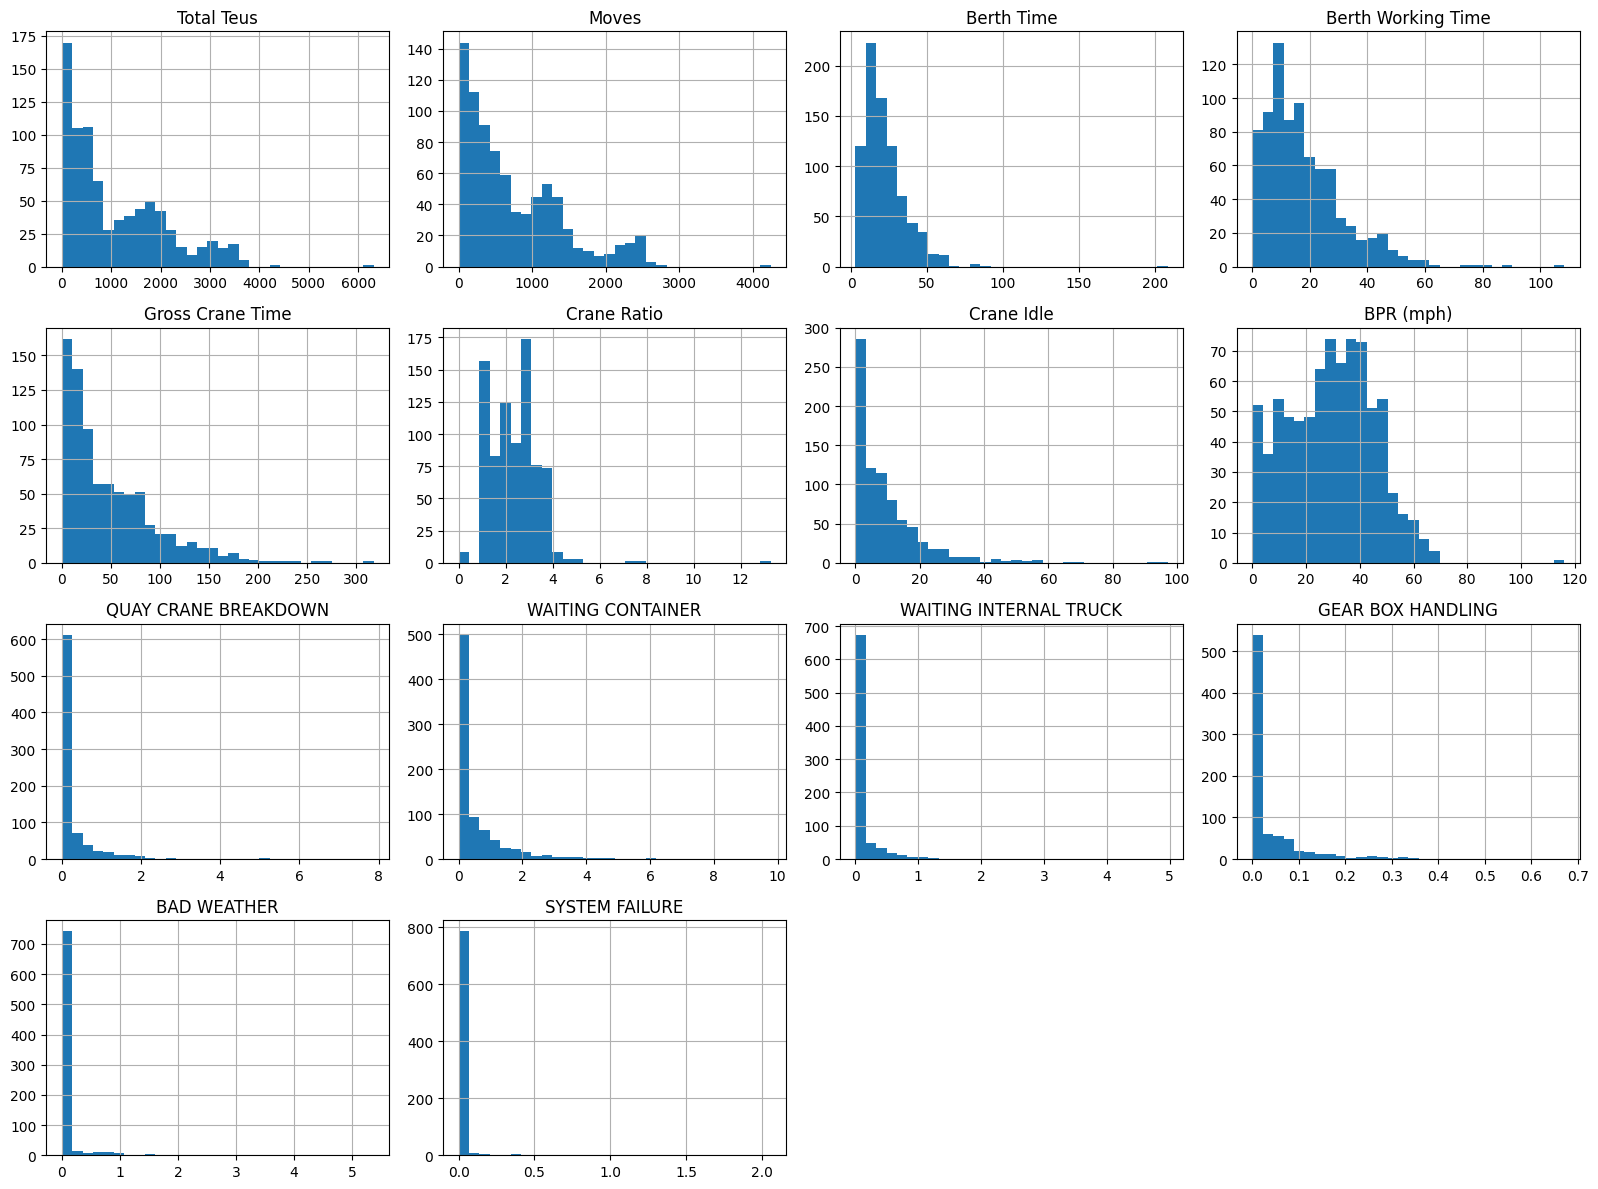

In [ ]:
X.hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

In [ ]:
skewness = X.skew().sort_values(ascending=False)

skewness

,0
SYSTEM FAILURE,16.275347
BAD WEATHER,7.941963
WAITING INTERNAL TRUCK,7.234225
QUAY CRANE BREAKDOWN,5.540916
WAITING CONTAINER,3.557934
Berth Time,3.410165
GEAR BOX HANDLING,3.215877
Crane Idle,2.694704
Crane Ratio,1.698059
Berth Working Time,1.531746


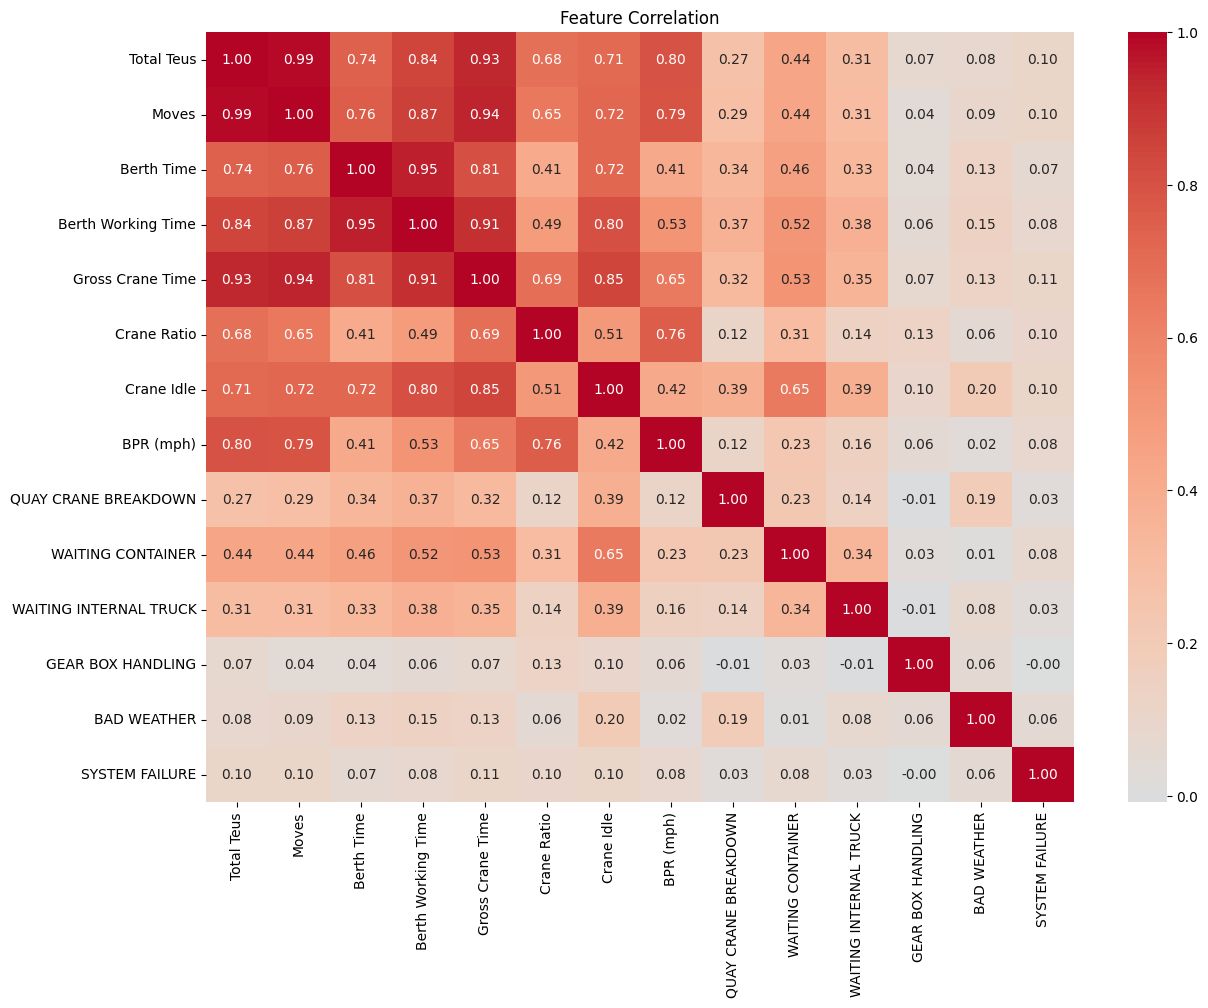

In [ ]:
corr = X.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation")
plt.show()

In [ ]:
corr_pairs = (
    X.corr()
    .where(np.triu(np.ones(X.corr().shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

corr_pairs[corr_pairs.abs() >= 0.70]

,,0
Total Teus,Moves,0.989812
Berth Time,Berth Working Time,0.951314
Moves,Gross Crane Time,0.944176
Total Teus,Gross Crane Time,0.931705
Berth Working Time,Gross Crane Time,0.908978
Moves,Berth Working Time,0.866043
Gross Crane Time,Crane Idle,0.845900
Total Teus,Berth Working Time,0.843269
Berth Time,Gross Crane Time,0.808621
Berth Working Time,Crane Idle,0.804346


In [ ]:
features = [
    "Total Teus",
    "Berth Time",
    "Gross Crane Time",
    "Crane Ratio",
    "Crane Idle",
    "BPR (mph)",
    "QUAY CRANE BREAKDOWN",
    "WAITING CONTAINER",
    "WAITING INTERNAL TRUCK",
    "GEAR BOX HANDLING",
    "BAD WEATHER",
    "SYSTEM FAILURE"
]

X = df[features].copy()

print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

Shape: (807, 12)
Missing values: 0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

X_scaled.head()

,Total Teus,Berth Time,Gross Crane Time,Crane Ratio,Crane Idle,BPR (mph),QUAY CRANE BREAKDOWN,WAITING CONTAINER,WAITING INTERNAL TRUCK,GEAR BOX HANDLING,BAD WEATHER,SYSTEM FAILURE
0,0.109760,-0.092917,-0.198197,-0.266284,-0.074536,0.609477,2.256065,-0.545194,-0.020592,1.605210,-0.223049,-0.115223
1,0.545511,0.242125,0.701086,1.248782,0.495961,0.720300,0.088179,-0.360367,-0.344370,2.026452,-0.223049,-0.115223
2,-0.574592,-0.840839,-0.621010,0.455377,-0.605934,0.095067,-0.286518,-0.428461,-0.344370,1.886038,-0.223049,-0.115223
3,-1.013644,-0.705468,-0.915048,-1.274307,-0.552616,-1.511563,-0.393574,-0.564649,-0.344370,3.149762,-0.223049,-0.115223
4,1.812134,1.759402,2.984707,1.829663,3.743886,1.000309,0.061415,-0.350640,0.214882,3.711417,-0.223049,-0.115223


In [ ]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

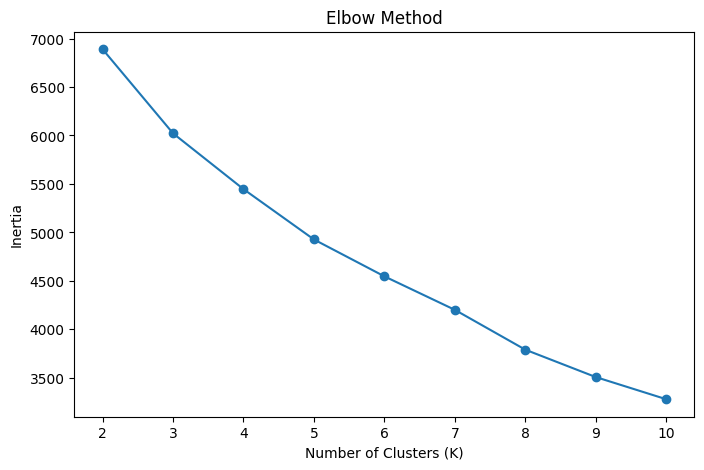

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(K_range, inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

In [ ]:
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k} → Silhouette Score = {score:.4f}")

K = 2 → Silhouette Score = 0.3564
K = 3 → Silhouette Score = 0.3234
K = 4 → Silhouette Score = 0.3495
K = 5 → Silhouette Score = 0.3192
K = 6 → Silhouette Score = 0.3181
K = 7 → Silhouette Score = 0.3161
K = 8 → Silhouette Score = 0.3274
K = 9 → Silhouette Score = 0.2385
K = 10 → Silhouette Score = 0.2452


In [ ]:
db_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = davies_bouldin_score(X_scaled, labels)
    db_scores.append(score)

for k, score in zip(range(2, 11), db_scores):
    print(f"K = {k} → Davies-Bouldin Score = {score:.4f}")

K = 2 → Davies-Bouldin Score = 1.2408
K = 3 → Davies-Bouldin Score = 1.6289
K = 4 → Davies-Bouldin Score = 1.2402
K = 5 → Davies-Bouldin Score = 1.2475
K = 6 → Davies-Bouldin Score = 1.2249
K = 7 → Davies-Bouldin Score = 1.3040
K = 8 → Davies-Bouldin Score = 1.1621
K = 9 → Davies-Bouldin Score = 1.1752
K = 10 → Davies-Bouldin Score = 1.1715


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch

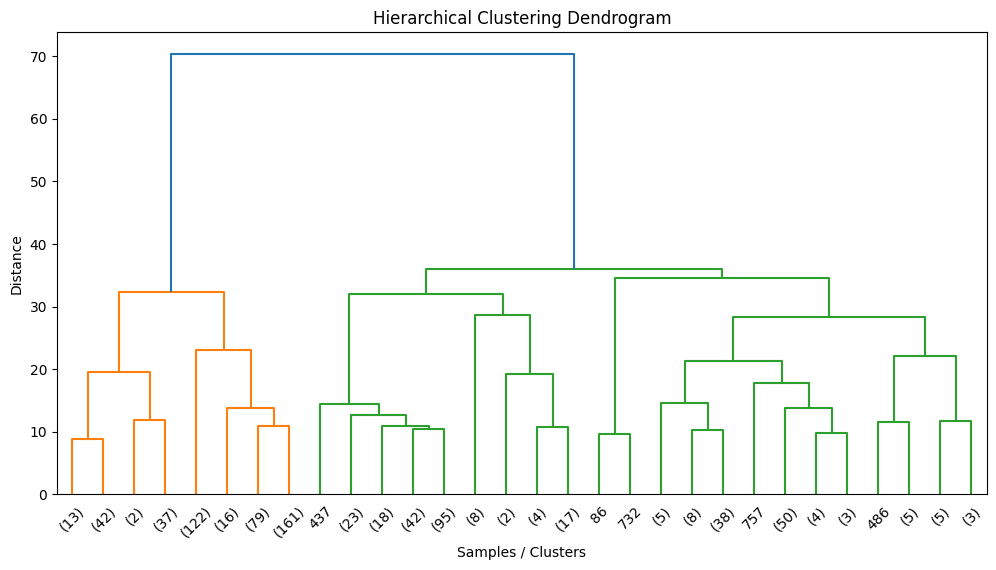

In [ ]:
plt.figure(figsize=(12, 6))

sch.dendrogram(
    sch.linkage(X_scaled, method="ward"),
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples / Clusters")
plt.ylabel("Distance")
plt.show()

In [ ]:
results = []

for k in range(2, 11):

    hierarchical = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = hierarchical.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)

    results.append((k, silhouette))

    print(f"K = {k} → Silhouette = {silhouette:.4f}")

K = 2 → Silhouette = 0.3258
K = 3 → Silhouette = 0.2720
K = 4 → Silhouette = 0.2778
K = 5 → Silhouette = 0.2550
K = 6 → Silhouette = 0.2562
K = 7 → Silhouette = 0.2653
K = 8 → Silhouette = 0.2728
K = 9 → Silhouette = 0.1975
K = 10 → Silhouette = 0.2007


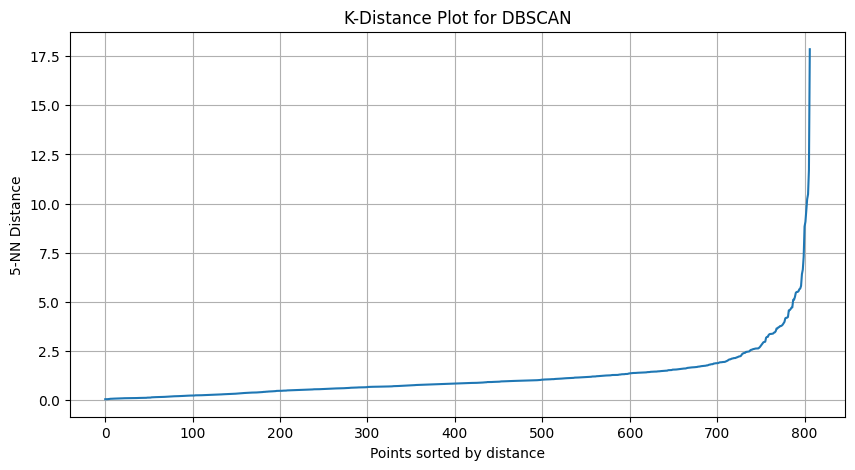

In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

k_distances = np.sort(distances[:, 4])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)

plt.xlabel("Points sorted by distance")
plt.ylabel("5-NN Distance")
plt.title("K-Distance Plot for DBSCAN")

plt.grid()
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = [0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.7, 2.0]
min_samples_values = [3, 5, 8]

for min_samples in min_samples_values:

    print(f"\nmin_samples = {min_samples}")

    for eps in eps_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        mask = labels != -1

        if n_clusters >= 2 and mask.sum() > n_clusters:
            silhouette = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )
            silhouette_text = f"{silhouette:.4f}"
        else:
            silhouette_text = "N/A"

        print(
            f"eps = {eps:<3} → "
            f"Clusters = {n_clusters:<2} | "
            f"Noise = {n_noise:<3} | "
            f"Silhouette = {silhouette_text}"
        )


min_samples = 3
eps = 0.5 → Clusters = 8  | Noise = 518 | Silhouette = 0.0072
eps = 0.7 → Clusters = 10 | Noise = 383 | Silhouette = -0.1870
eps = 0.9 → Clusters = 9  | Noise = 277 | Silhouette = -0.0043
eps = 1.1 → Clusters = 8  | Noise = 201 | Silhouette = -0.0134
eps = 1.3 → Clusters = 3  | Noise = 144 | Silhouette = 0.0659
eps = 1.5 → Clusters = 2  | Noise = 110 | Silhouette = 0.3663
eps = 1.7 → Clusters = 1  | Noise = 88  | Silhouette = N/A
eps = 2.0 → Clusters = 1  | Noise = 71  | Silhouette = N/A

min_samples = 5
eps = 0.5 → Clusters = 3  | Noise = 559 | Silhouette = 0.2037
eps = 0.7 → Clusters = 6  | Noise = 422 | Silhouette = 0.0399
eps = 0.9 → Clusters = 4  | Noise = 313 | Silhouette = 0.0215
eps = 1.1 → Clusters = 2  | Noise = 235 | Silhouette = 0.4394
eps = 1.3 → Clusters = 4  | Noise = 171 | Silhouette = 0.1999
eps = 1.5 → Clusters = 2  | Noise = 123 | Silhouette = 0.3805
eps = 1.7 → Clusters = 1  | Noise = 93  | Silhouette = N/A
eps = 2.0 → Clusters = 1  | Noise = 74  | 

In [ ]:
dbscan = DBSCAN(
    eps=1.1,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

df["DBSCAN_Cluster"] = dbscan_labels

print(df["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1    235
 0    567
 1      5
Name: count, dtype: int64


/tmp/ipykernel_3025/3999528560.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["DBSCAN_Cluster"] = dbscan_labels


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance, start=1):
    print(f"PC{i}: {variance:.4f}")

print(f"\nTotal variance explained by 2 PCs: {explained_variance[:2].sum():.4f}")

PC1: 0.4193
PC2: 0.1120
PC3: 0.0899
PC4: 0.0833
PC5: 0.0790
PC6: 0.0669
PC7: 0.0535
PC8: 0.0447
PC9: 0.0229
PC10: 0.0176
PC11: 0.0091
PC12: 0.0017

Total variance explained by 2 PCs: 0.5314


In [ ]:
pca = PCA(n_components=0.90)

X_pca = pca.fit_transform(X_scaled)

print("Number of components:", X_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

Number of components: 7
Explained variance: 0.9039701039384372


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca)

    silhouette = silhouette_score(X_pca, labels)

    print(f"K = {k} → Silhouette = {silhouette:.4f}")

K = 2 → Silhouette = 0.3883
K = 3 → Silhouette = 0.3837
K = 4 → Silhouette = 0.3650
K = 5 → Silhouette = 0.3869
K = 6 → Silhouette = 0.3770
K = 7 → Silhouette = 0.3763
K = 8 → Silhouette = 0.3710
K = 9 → Silhouette = 0.2848
K = 10 → Silhouette = 0.2905


In [ ]:
for k in [2, 3, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_pca)

    print(f"\nK = {k}")
    print(pd.Series(labels).value_counts().sort_index())


K = 2
0    464
1    343
Name: count, dtype: int64

K = 3
0    445
1     55
2    307
Name: count, dtype: int64

K = 5
0    288
1    415
2     52
3      2
4     50
Name: count, dtype: int64


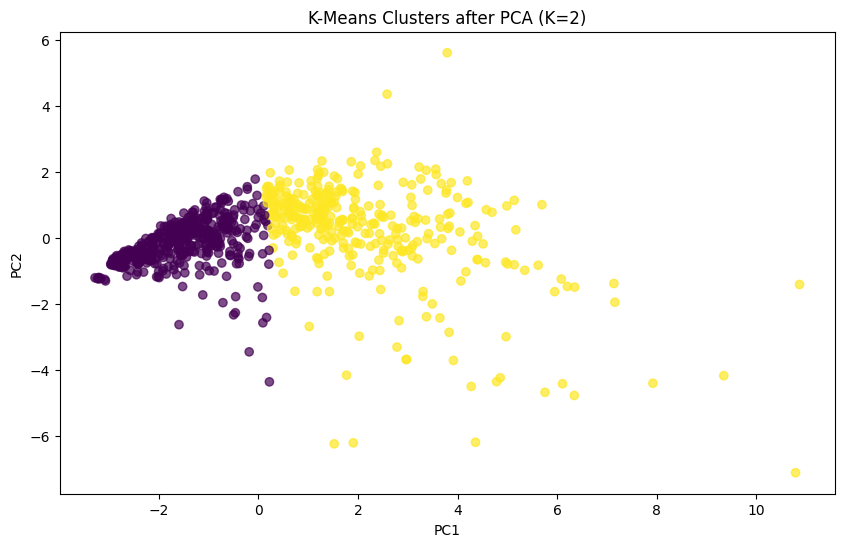

In [ ]:
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

final_labels = kmeans_final.fit_predict(X_pca)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=final_labels,
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means Clusters after PCA (K=2)")
plt.show()